In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_pickle('pilot_results.pkl')

In [3]:
#subjects_decisions contains subject decisions for each subject
#the first column contains number of accumulated wins, the second contains accumulated fails
#the third is boolean and contains 1 if subject decided to change the button and 0 if subject decided to stay
#the fourth contains the number of remaining presses
subjects_decisions = []
#subjects_button_activity contains accumulated buttons wins, fails and remaining presses for all the subjects per button
subjects_button_activity = []
for subject in df['press_data']:
    record = np.array([[el['button_number'],el['outcome']] for el in subject])
    button_split = [record[record[:,0]==k,1] for k in np.unique(record[:,0])]
    decisions = [np.vstack([np.cumsum(elt),
                                np.arange(1,len(elt)+1)-np.cumsum(elt),
                                np.eye(1,M=len(elt),k=len(elt)-1)]).T for elt in button_split]
    button_split_pos = np.cumsum([len(el) for el in decisions])[:-1]
    decisions = np.concatenate(decisions)
    decisions = np.c_[decisions, np.arange(len(decisions))[::-1]]
    subjects_decisions.append(decisions[:-1])
    subjects_button_activity.append(np.split(decisions[:,[0,1,3]], button_split_pos))
    
decisions = np.concatenate(subjects_decisions)
decisions = decisions[np.lexsort((decisions[:,3], decisions[:,2], decisions[:,1], decisions[:,0]))].astype(int)

In [4]:
first_button_switch = np.array([el[0][-1] for el in subjects_button_activity])

In [5]:
print(first_button_switch[first_button_switch[:,1] > first_button_switch[:,0]])

[[ 0.  7. 33.]
 [ 2.  4. 34.]
 [ 0.  1. 39.]
 [ 0.  4. 36.]
 [ 0.  2. 38.]
 [ 0.  4. 36.]
 [ 0.  3. 37.]
 [ 0.  6. 34.]
 [ 0.  3. 37.]
 [ 1.  3. 36.]
 [ 1.  3. 36.]
 [ 0.  2. 38.]
 [ 1.  2. 37.]
 [ 0.  2. 38.]
 [ 2.  3. 35.]
 [ 0.  2. 38.]
 [ 0.  3. 37.]
 [ 4.  5. 31.]
 [ 6.  7. 27.]
 [ 0.  2. 38.]
 [ 4.  5. 31.]
 [ 1.  2. 37.]
 [ 1.  2. 37.]
 [ 1.  4. 35.]
 [ 4.  6. 30.]
 [10. 20. 10.]
 [ 0.  2. 38.]
 [ 8. 32.  0.]
 [ 0.  3. 37.]]


In [6]:
print(np.array([el[-1][-1] for el in subjects_button_activity]))

[[ 4.  1.  0.]
 [14.  2.  0.]
 [35.  3.  0.]
 [ 2.  0.  0.]
 [ 4.  0.  0.]
 [12. 24.  0.]
 [15.  1.  0.]
 [ 3.  1.  0.]
 [28.  6.  0.]
 [13.  6.  0.]
 [ 5.  1.  0.]
 [18.  6.  0.]
 [ 5.  5.  0.]
 [26. 14.  0.]
 [ 2.  1.  0.]
 [23.  5.  0.]
 [27.  7.  0.]
 [33.  7.  0.]
 [19.  6.  0.]
 [11.  1.  0.]
 [17. 13.  0.]
 [ 0.  2.  0.]
 [15.  3.  0.]
 [33.  7.  0.]
 [ 2.  0.  0.]
 [27. 13.  0.]
 [ 4. 17.  0.]
 [32.  8.  0.]
 [ 0.  1.  0.]
 [31.  9.  0.]
 [ 2.  1.  0.]
 [20.  2.  0.]
 [17. 10.  0.]
 [18.  6.  0.]
 [ 2.  0.  0.]
 [ 1.  0.  0.]
 [ 2.  3.  0.]
 [23. 12.  0.]
 [19.  3.  0.]
 [27.  8.  0.]
 [15.  5.  0.]
 [ 2.  4.  0.]
 [ 9.  1.  0.]
 [ 0.  1.  0.]
 [25. 10.  0.]
 [ 8. 32.  0.]
 [28. 12.  0.]
 [21.  8.  0.]
 [36.  4.  0.]
 [ 3.  2.  0.]]


In [7]:
out1, out2 = np.unique(decisions[:,:2], axis=0, return_counts=True)
total_counts = np.c_[out1, out2]

In [8]:
print(total_counts[total_counts[:,0]<10])

[[  0   1 120]
 [  0   2  68]
 [  0   3  39]
 [  0   4  16]
 [  0   5   9]
 [  0   6   6]
 [  0   7   3]
 [  0   8   2]
 [  0   9   2]
 [  0  10   2]
 [  0  11   2]
 [  0  12   2]
 [  0  13   2]
 [  0  14   1]
 [  1   0 130]
 [  1   1  74]
 [  1   2  47]
 [  1   3  30]
 [  1   4  13]
 [  1   5   6]
 [  1   6   2]
 [  1  13   1]
 [  1  14   1]
 [  2   0  69]
 [  2   1  45]
 [  2   2  25]
 [  2   3  19]
 [  2   4  14]
 [  2   5   9]
 [  2   6   7]
 [  2   7   5]
 [  2   8   1]
 [  2   9   1]
 [  2  13   1]
 [  2  14   2]
 [  3   0  44]
 [  3   1  35]
 [  3   2  21]
 [  3   3  14]
 [  3   4   8]
 [  3   5   6]
 [  3   6   1]
 [  3   7   2]
 [  3   8   1]
 [  3   9   1]
 [  3  10   1]
 [  3  14   2]
 [  3  15   2]
 [  3  16   1]
 [  3  17   1]
 [  3  18   1]
 [  3  19   1]
 [  4   0  27]
 [  4   1  21]
 [  4   2  15]
 [  4   3   5]
 [  4   4   6]
 [  4   5   8]
 [  4   6   4]
 [  4   7   2]
 [  4   8   2]
 [  4   9   1]
 [  4  10   1]
 [  4  15   1]
 [  4  16   1]
 [  4  19   1]
 [  4  20 

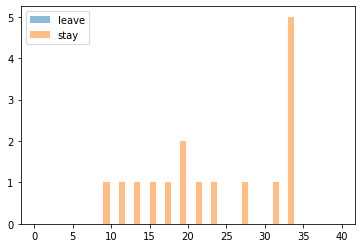

In [9]:
wins, fails = 6, 2
choise = decisions[np.logical_and(decisions[:,0]==wins,decisions[:,1]==fails)][:,2:]
leave = choise[choise[:,0]==1][:,1]
stay = choise[choise[:,0]==0][:,1]

plt.hist([leave, stay], alpha=0.5, label=["leave", "stay"], range=[0.0, 40.0], bins=20)
plt.legend(loc="upper left")
plt.show()